# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [3]:
# Check the size of the dataset
print(df.shape)

# Check column information
df.info()

# Check missing values
df.isnull().sum()


(100000, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      100000 non-null  int64  
 1   movie_id     100000 non-null  int64  
 2   rating       100000 non-null  int64  
 3   timestamp    100000 non-null  object 
 4   age          100000 non-null  int64  
 5   gender       100000 non-null  object 
 6   occupation   100000 non-null  object 
 7   zip_code     100000 non-null  object 
 8   title        100000 non-null  object 
 9   year         99970 non-null   float64
 10  decade       99970 non-null   float64
 11  genres       100000 non-null  object 
 12  rating_year  100000 non-null  int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 9.9+ MB


user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
title           0
year           30
decade         30
genres          0
rating_year     0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.describe()

,user_id,movie_id,rating,age,year,decade,rating_year
count,100000.00000,100000.000000,100000.000000,100000.000000,99970.000000,99970.000000,100000.000000
mean,462.48475,425.530130,3.529860,32.969850,1987.748224,1982.780134,1997.471010
std,266.61442,330.798356,1.125674,11.562623,14.140014,13.820687,0.499161
min,1.00000,1.000000,1.000000,7.000000,1922.000000,1920.000000,1997.000000
25%,254.00000,175.000000,3.000000,24.000000,1986.000000,1980.000000,1997.000000
50%,447.00000,322.000000,4.000000,30.000000,1994.000000,1990.000000,1997.000000
75%,682.00000,631.000000,4.000000,40.000000,1996.000000,1990.000000,1998.000000
max,943.00000,1682.000000,5.000000,73.000000,1998.000000,1990.000000,1998.000000



**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

I checked the dataset and found that it has 100,000 rows and 13 columns. Most of the data is complete, but the year and decade columns each have 30 missing values. I don't think this will affect most of my analysis, but I'll leave those rows out when looking at ratings by release year.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: I'll count the movies instead of the ratings. If a movie has more than one genre, I'll include it in each genre.
- Why: I want to see how many movies belong to each genre without counting the same movie multiple times just because people rated it more.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: I'll find the average rating for each genre and check how many ratings each one has
- Why: Some genres might have higher averages just because they have fewer ratings, so I want to take that into consideration.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: I'll compare the average ratings by movie release year and leave out the rows with missing years.
- Why: I noticed 30 missing values in the year column, and I also want to see how many ratings each year has so the comparison is fair.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: I'll calculate each movie's average rating and only include movies with at least 50 ratings. Then I'll compare that with a minimum of 150 ratings. If two movies have the same average, I'll put the one with more ratings first.
- Why: A movie with only a few ratings might have a really high average, so using a minimum number of ratings should make the results more reliable.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

genre
Drama          725
Comedy         505
Thriller       251
Action         251
Romance        247
Adventure      135
Children       122
Crime          109
Sci-Fi         101
Horror          92
War             71
Mystery         61
Musical         56
Documentary     50
Animation       42
Western         27
Film-Noir       24
Fantasy         22
unknown          2
Name: count, dtype: int64


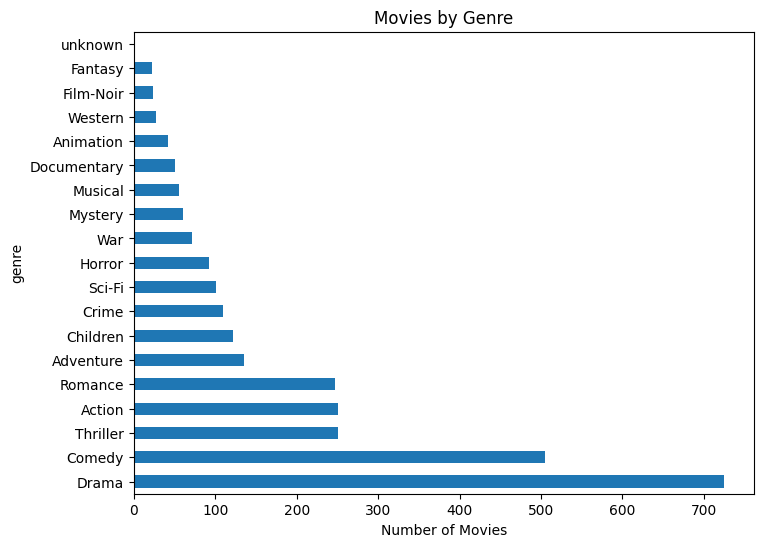

In [6]:
# Q1: your code here


movies = df.drop_duplicates(subset='movie_id')

genre_df = movies.assign(genre=movies['genres'].str.split('|')).explode('genre')

genre_counts = genre_df['genre'].value_counts()

print(genre_counts)

genre_counts.plot(kind='barh', figsize=(8, 6), title='Movies by Genre')
plt.xlabel('Number of Movies')
plt.show()

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

Drama had the most movies with 725, followed by Comedy with 505. Thriller and Action both had 251 movies, while Romance had 247. I counted unique movies instead of ratings, and movies with more than one genre were included in each genre they belonged to. Drama had 220 more movies than Comedy, so it was clearly the most common genre.


## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

                 mean  count
genre                       
Film-Noir    3.921523   1733
War          3.815812   9398
Drama        3.687379  39895
Documentary  3.672823    758
Mystery      3.638132   5245
Crime        3.632278   8055
Romance      3.621705  19461
Western      3.613269   1854
Animation    3.576699   3605
Sci-Fi       3.560723  12730
Musical      3.521397   4954
Thriller     3.509007  21872
Adventure    3.503527  13753
Action       3.480245  25589
Comedy       3.394073  29832
Children     3.353244   7182
Horror       3.290389   5317
Fantasy      3.215237   1352
unknown      3.200000     10


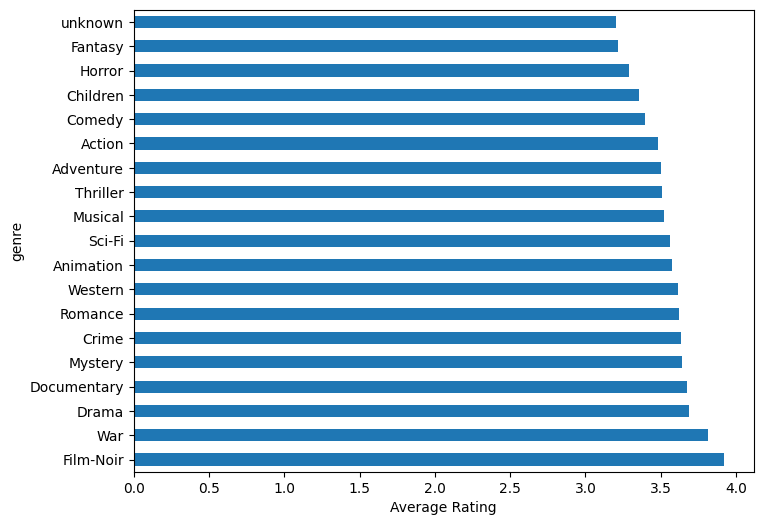

In [9]:
# Q2: your code here
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')

genre_ratings = genre_df.groupby('genre')['rating'].agg(['mean', 'count'])

genre_ratings = genre_ratings.sort_values('mean', ascending=False)

print(genre_ratings)

genre_ratings['mean'].plot(kind='barh', figsize=(8, 6))
plt.xlabel('Average Rating')
plt.show()

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

Film Noir had the highest average rating at 3.92 with 1,733 ratings, followed by War at 3.82 with 9,398 ratings. The lowest was unknown at 3.20, but it only had 10 ratings. Fantasy was the lowest actual genre at 3.22 with 1,352 ratings, followed by Horror at 3.29 with 5,317 ratings. I also looked at the number of ratings because genres with fewer ratings might not give as reliable of an average.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

            mean  count
year                   
1922.0  3.555556     54
1926.0  3.000000      2
1930.0  3.777778     18
1931.0  4.000000     44
1932.0  3.833333     12
...          ...    ...
1994.0  3.420080   9034
1995.0  3.414642  12389
1996.0  3.311086  18744
1997.0  3.312467  15384
1998.0  3.297297    851

[71 rows x 2 columns]


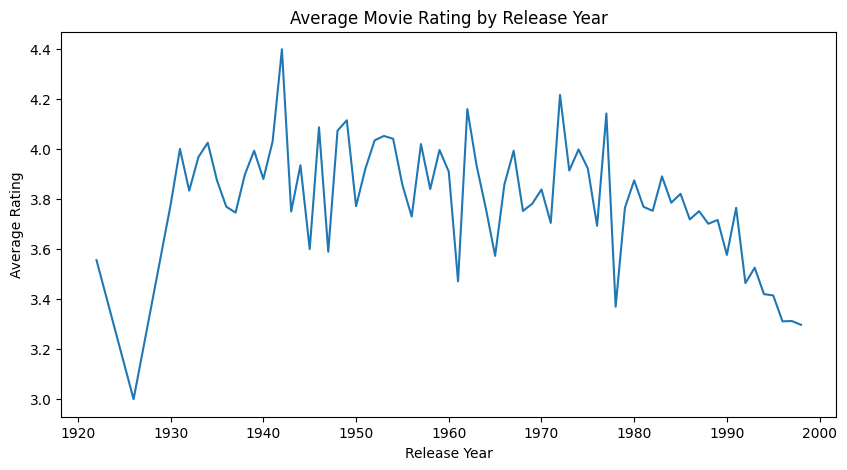

In [11]:
# Q3: your code here
year_ratings = df.groupby('year')['rating'].agg(['mean', 'count'])

year_ratings = year_ratings.sort_index()

print(year_ratings)

year_ratings['mean'].plot(kind='line', figsize=(10, 5))
plt.title('Average Movie Rating by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Average Rating')
plt.show()

**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

The average movie ratings seem to decrease over time. For example, movies released in 1931 had an average rating of 4.00, while movies from 1996 had an average of 3.31. However, 1931 only had 44 ratings compared to 18,744 in 1996. This shows that some years have a lot more ratings than others, so the averages from years with fewer ratings might not be as reliable.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [14]:
# Q4: your code here
movie_ratings = df.groupby(['movie_id', 'title'])['rating'].agg(['mean', 'count'])

top_50 = movie_ratings[movie_ratings['count'] >= 50]
top_50 = top_50.sort_values(['mean', 'count'], ascending=False).head(5)

top_150 = movie_ratings[movie_ratings['count'] >= 150]
top_150 = top_150.sort_values(['mean', 'count'], ascending=False).head(5)

print("Top 5 Movies with at least 50 ratings:")
print(top_50)

print("\nTop 5 Movies with at least 150 ratings:")
print(top_150)

Top 5 Movies with at least 50 ratings:
                                                                 mean  count
movie_id title                                                              
408      Close Shave, A (1995)                               4.491071    112
318      Schindler's List (1993)                             4.466443    298
169      Wrong Trousers, The (1993)                          4.466102    118
483      Casablanca (1942)                                   4.456790    243
114      Wallace & Gromit: The Best of Aardman Animation...  4.447761     67

Top 5 Movies with at least 150 ratings:
                                               mean  count
movie_id title                                            
318      Schindler's List (1993)           4.466443    298
483      Casablanca (1942)                 4.456790    243
64       Shawshank Redemption, The (1994)  4.445230    283
603      Rear Window (1954)                4.387560    209
12       Usual Suspects, Th

**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_

With at least 50 ratings, the top 5 movies were A Close Shave (4.49), Schindler's List (4.47), The Wrong Trousers (4.47), Casablanca (4.46), and Wallace & Gromit: The Best of Aardman Animation (4.45).

When I increased the minimum to 150 ratings, the top 5 changed to Schindler's List (4.47), Casablanca (4.46), The Shawshank Redemption (4.45), Rear Window (4.39), and The Usual Suspects (4.39).

A Close Shave, The Wrong Trousers, and Wallace & Gromit dropped out because they had fewer than 150 ratings. This shows that movies with fewer ratings can have really high averages, but increasing the minimum helps us compare movies with more ratings behind their scores.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked: I asked Cursor to help me plan a MovieLens dashboard using Python and Streamlit. I wanted it to answer all four required questions, have at least two interactive controls, and be beginner-friendly. I asked it to make a plan before writing any code.

- AI's first attempt:Cursor gave me a project plan with the files I needed, how to handle movies with multiple genres, and what charts to use for each question. It also suggested a year slider and other filters.

- What I changed (or accepted without checking): I liked the plan overall, so I approved it. One thing I changed was Question 4 because I wanted the results for 50 ratings and 150 ratings shown side by side instead of only using a slider. I also told Cursor not to deploy the app yet.

**Prompt 2**
- What I asked: I asked Cursor to follow the plan and build the dashboard using simple Python, pandas, and Streamlit. I wanted all four questions answered, both rating thresholds displayed, and the prompts saved in a build log. 
- AI's first attempt: Cursor created the dashboard with four chart sections, a release-year slider, and a genre filter. It also displayed the top five movies for both the 50-rating and 150-rating requirements. 

- What I changed (or accepted without checking): When I first ran the dashboard, I noticed the genre chart was sorted alphabetically instead of by the number of movies. I had Cursor fix it so the genres with the most movies appeared first. I also had it round the movie ratings to three decimal places and remove the movie IDs from the tables to make them easier to read.

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: Drama has the most movies with 725, followed by Comedy with 505.
- I say: Drama has 725 movies and Comedy has 505. Both are the most common genres.
- Same? (yes / partly / no): YES
- If different, why? 

**Q2**
- Dashboard says: Film-Noir has the highest average rating at 3.92, and unknown has the lowest at 3.20.
- I say: Film-Noir has the highest average at 3.92, followed by War at 3.82. Unknown is the lowest at 3.20, but it only has 10 ratings.
- Same? (yes / partly / no): YES
- If different, why? 

**Q3**
- Dashboard says: Average ratings change across release years, but older movies generally have higher ratings than newer movies.
- I say: Ratings go up and down over time. For example, 1931 had an average of 4.00 from 44 ratings, while 1997 had 3.31 from 15,384 ratings.
- Same? (yes / partly / no): YES
- If different, why?

**Q4**
- Dashboard says: With at least 50 ratings, A Close Shave ranks first at 4.491. With at least 150 ratings, Schindler's List ranks first at 4.466.
- I say: A Close Shave ranks first with 112 ratings when the minimum is 50. When the minimum increases to 150, Schindler's List becomes first with 298 ratings.
- Same? (yes / partly / no): YES
- If different, why?

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

**Q1:**

My results matched because both the dashboard and my code counted unique movies instead of individual ratings. They also separated movies with multiple genres, so a movie could count toward more than one genre. Both showed Drama with 725 movies and Comedy with 505, which makes me more confident in the results.

**Q4:**

My results matched because both methods used the same minimum rating requirements. With at least 50 ratings, A Close Shave ranked first with 4.491, but when the minimum increased to 150, Schindler's List ranked first with 4.466. I trust these results because increasing the minimum removes movies that don't have enough ratings.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Horizontal bar chart.
- Chart I used: Horizontal bar chart.
- Which communicates the answer better, and why? Both work well because the genres are sorted by the number of movies. The horizontal bars also make the genre names easy to read.

**Q2**
- Chart the dashboard used: Horizontal bar chart.
- Chart I used: Horizontal bar chart and table.
- Which communicates the answer better, and why? I think mine is a little better because the table also shows how many ratings each average is based on. This helps show which averages are more reliable.

**Q3**
- Chart the dashboard used: Line chart.
- Chart I used: Line chart and table.
- Which communicates the answer better, and why? Both charts show how ratings change over time, but mine also includes a table showing the number of ratings for each year. This is helpful because some years have fewer ratings than others.

**Q4**
- Chart the dashboard used: Horizontal bar charts and tables.
- Chart I used: Tables.
- Which communicates the answer better, and why? I think the tables are better because they show the exact average rating and number of ratings for each movie. This makes it easier to compare the top five movies when the minimum changes from 50 to 150.


Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

Overall, I think the charts do a good job showing the results. Most of them are sorted correctly, the labels are readable, and the axes are clear and start at zero where appropriate. However, some charts don't show how many ratings each average is based on, which can be misleading. I think including the rating counts makes the results easier to understand and more trustworthy.

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

**3. What can Q3 really say about time?**

My dashboard shows how average ratings differ based on the year movies were released, not how people's opinions changed over time. Older movies might have higher ratings because people are more likely to watch and rate older movies that are already considered classics. So I can't really say that older movies were better just because they have higher ratings.

**5. Deployment risk**

A studio executive might assume Film-Noir is the best genre to produce because it has the highest average rating of 3.92. However, that doesn't mean it would be the most popular or successful genre today.

**Caveat:** These ratings only reflect the users in this dataset and don't necessarily represent everyone's movie preferences.

**1. Who is in this data?**

The dataset only includes people who submitted movie ratings, so it doesn't represent everyone who watches movies. People who rate movies frequently might have different preferences from casual viewers who rarely leave ratings. This could affect my Q2 results because certain genres might receive higher ratings based on the types of users included in the dataset.

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better): The AI originally made the genre chart alphabetical, which made it harder to see which genres were most common. I changed it to sort from highest to lowest so the results were easier to compare.

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right): The AI did a good job handling movies with multiple genres by separating them before counting. It also correctly used movie release years instead of rating years for the time trend chart.

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when? The AI did most of the initial coding in Week 4, but I guided what I wanted and tested the results. In Week 6, I took more control by reviewing the charts, checking the results, and deciding what worked and what needed improvement.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week